In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Linear Regression Model
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
# Train Test packages
from sklearn.model_selection import train_test_split, KFold , cross_val_score
#Feature Scaling
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
#Pipeline
from sklearn.pipeline import Pipeline
#Metrics
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score


In [3]:
df = pd.read_csv('Dataset/Real estate.csv')
df.head()

,No,X1 transaction date,X2 house age,X3 distance to the nearest MRT station,X4 number of convenience stores,X5 latitude,X6 longitude,Y house price of unit area
0,1,2012.917,32.0,84.87882,10,24.98298,121.54024,37.9
1,2,2012.917,19.5,306.59470,9,24.98034,121.53951,42.2
2,3,2013.583,13.3,561.98450,5,24.98746,121.54391,47.3
3,4,2013.500,13.3,561.98450,5,24.98746,121.54391,54.8
4,5,2012.833,5.0,390.56840,5,24.97937,121.54245,43.1


In [4]:
df.isnull().sum()

No                                        0
X1 transaction date                       0
X2 house age                              0
X3 distance to the nearest MRT station    0
X4 number of convenience stores           0
X5 latitude                               0
X6 longitude                              0
Y house price of unit area                0
dtype: int64

In [5]:
df.columns

Index(['No', 'X1 transaction date', 'X2 house age',
       'X3 distance to the nearest MRT station',
       'X4 number of convenience stores', 'X5 latitude', 'X6 longitude',
       'Y house price of unit area'],
      dtype='object')

<Axes: ylabel='X6 longitude'>

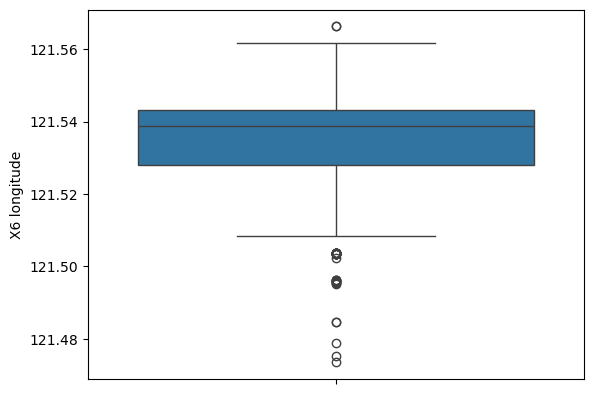

In [6]:
sns.boxplot(df['X6 longitude'])

In [7]:
df= df.drop(columns=['No','X1 transaction date'])


In [8]:
df

,X2 house age,X3 distance to the nearest MRT station,X4 number of convenience stores,X5 latitude,X6 longitude,Y house price of unit area
0,32.0,84.87882,10,24.98298,121.54024,37.9
1,19.5,306.59470,9,24.98034,121.53951,42.2
2,13.3,561.98450,5,24.98746,121.54391,47.3
3,13.3,561.98450,5,24.98746,121.54391,54.8
4,5.0,390.56840,5,24.97937,121.54245,43.1
...,...,...,...,...,...,...
409,13.7,4082.01500,0,24.94155,121.50381,15.4
410,5.6,90.45606,9,24.97433,121.54310,50.0
411,18.8,390.96960,7,24.97923,121.53986,40.6
412,8.1,104.81010,5,24.96674,121.54067,52.5


In [9]:
#df_corr = df.corr(method='Spearson')
df_corr = df.corr(method='pearson')
df_corr

,X2 house age,X3 distance to the nearest MRT station,X4 number of convenience stores,X5 latitude,X6 longitude,Y house price of unit area
X2 house age,1.000000,0.025622,0.049593,0.054420,-0.048520,-0.210567
X3 distance to the nearest MRT station,0.025622,1.000000,-0.602519,-0.591067,-0.806317,-0.673613
X4 number of convenience stores,0.049593,-0.602519,1.000000,0.444143,0.449099,0.571005
X5 latitude,0.054420,-0.591067,0.444143,1.000000,0.412924,0.546307
X6 longitude,-0.048520,-0.806317,0.449099,0.412924,1.000000,0.523287
Y house price of unit area,-0.210567,-0.673613,0.571005,0.546307,0.523287,1.000000


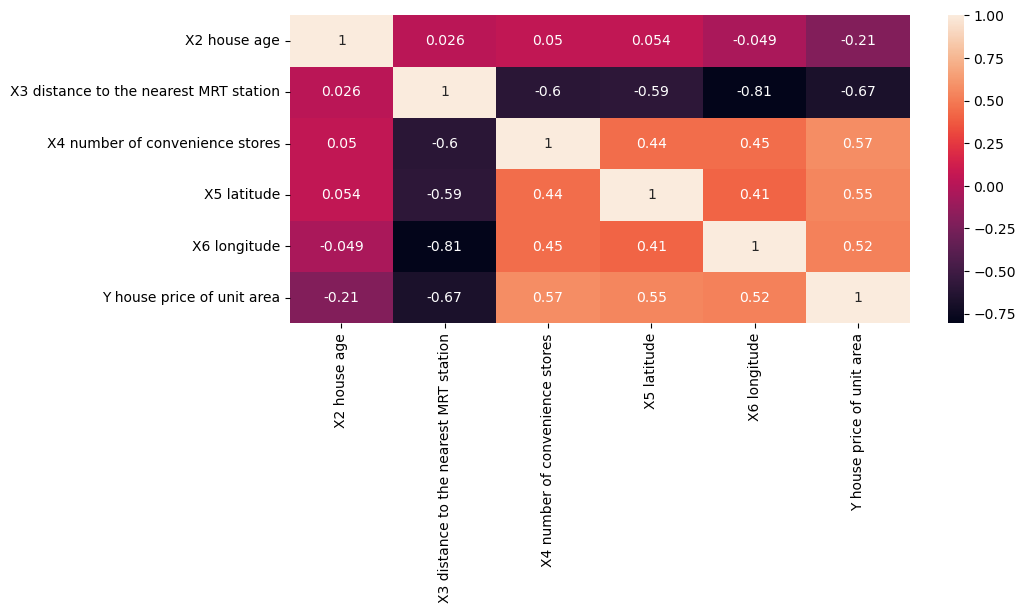

In [10]:
plt.figure(figsize=(10,4))
sns.heatmap(df_corr,annot=True)
plt.show()

# feature and Target

In [11]:
df.columns

Index(['X2 house age', 'X3 distance to the nearest MRT station',
       'X4 number of convenience stores', 'X5 latitude', 'X6 longitude',
       'Y house price of unit area'],
      dtype='object')

In [12]:
features=['X2 house age', 'X3 distance to the nearest MRT station',
       'X4 number of convenience stores', 'X5 latitude', 'X6 longitude']
target = 'Y house price of unit area'

In [13]:
X = df[features]
Y = df[target]

# Train Test Split

In [14]:
X_train,X_test,Y_train,Y_test = train_test_split(
   X, Y, test_size = 0.2 , random_state = 42
    
)

# Feature Scaling

In [15]:
'''
scaler.fit_transfrom(X_train)
  ->fit_transform(training data)
  ->fit->Learning->Calculates mean and sd
  ->Transform -> Implement->Implement mean and sd into fromula ((Xi - mean)/sd)

  scaler.transform(X_test)
  ->transform(testing data)
  ->transform -> implement->((Xi - mean)/sd)


'''

'\nscaler.fit_transfrom(X_train)\n  ->fit_transform(training data)\n  ->fit->Learning->Calculates mean and sd\n  ->Transform -> Implement->Implement mean and sd into fromula ((Xi - mean)/sd)\n\n  scaler.transform(X_test)\n  ->transform(testing data)\n  ->transform -> implement->((Xi - mean)/sd)\n\n\n'

In [16]:
scaler = StandardScaler()
X_train_scale = scaler.fit_transform(X_train)
X_test_scale = scaler.transform(X_test)

In [17]:
X_train_scale

array([[ 2.34401494, -0.82396519,  0.96804159, -0.14706597,  0.45505725],
       [-0.82128138,  0.9514177 , -0.04917037, -0.74311697, -1.35592638],
       [-0.90085586,  0.91722447, -0.38824102, -0.50405479, -1.42748297],
       ...,
       [-0.5737163 , -0.66362097, -1.06638232,  0.4225117 , -0.22907726],
       [-1.12189611, -0.65780025,  0.62897094,  0.52278946,  0.75398992],
       [-1.43135245, -0.71213528,  0.62897094, -0.29066372,  0.46843231]],
      shape=(331, 5))

# Model Implementaton 

In [18]:
model = LinearRegression()

In [19]:
'''
-X_train -> Question
-Y_train -> Answer

- X_test -> Exam Question

- fit (training data ) -> X_train , Y_train -> Model Learning Phase
-predict(testing data)-> X_test




'''

'\n-X_train -> Question\n-Y_train -> Answer\n\n- X_test -> Exam Question\n\n- fit (training data ) -> X_train , Y_train -> Model Learning Phase\n-predict(testing data)-> X_test\n\n\n\n\n'

In [20]:
model.fit(X_train,Y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [21]:
Y_pred = model.predict(X_test_scale)
# Y_pred

C:\Users\Admin\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


In [22]:
beta_0 = model.intercept_
beta_1 = model.coef_

print(f'intercept:{beta_0}')
print(f'slope/Coefficient:{beta_1}')

intercept:-2946.6588590244423
slope/Coefficient:[-2.70593236e-01 -4.55249601e-03  1.10512079e+00  2.36092831e+02
 -2.39036942e+01]


## Adjusting R2 Score

In [23]:
 def adjust_r2_score(r2,n,p):
      return 1 -(1- r2) * (n - 1)/(n- p- 1)

In [24]:
n_sample = X_test_scale.shape[0]
p_data = X_train.shape[1]

# Metrics

In [25]:
mae = mean_absolute_error(Y_test,Y_pred)
mse= mean_squared_error(Y_test,Y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(Y_test,Y_pred)
adjust_r2 = adjust_r2_score(r2,n_sample,p_data)

In [26]:
print(f'Mean Absolute Error:{mae}')
print(f'Mean Squared Error:{mse}')
print(f'Root Mean Squared Error:{rmse}')
print(f'R2 Score:{r2}')
print(f'Adjusted R2 Score:{adjust_r2}')

Mean Absolute Error:3007.6035753841006
Mean Squared Error:9089778.052546784
Root Mean Squared Error:3014.9258784498807
R2 Score:-54182.308865552004
Adjusted R2 Score:-57700.70554513331


# visualization

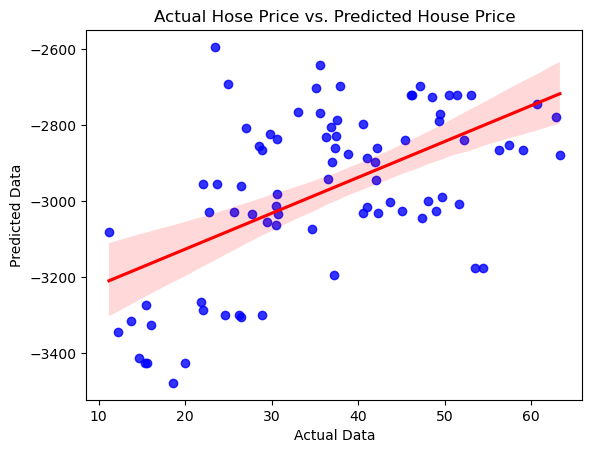

In [27]:
sns.regplot(x=Y_test, y= Y_pred, color = 'blue',line_kws={'color':'red'})
plt.xlabel('Actual Data')
plt.ylabel('Predicted Data')
plt.title('Actual Hose Price vs. Predicted House Price')
plt.show()

In [28]:
df = pd.read_csv('Dataset/Car_Sales.csv')
df.head()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,Maruti 800 AC,2007,60000,70000,Petrol,Individual,Manual,First Owner
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,Individual,Manual,First Owner
2,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,Individual,Manual,First Owner
3,Datsun RediGO T Option,2017,250000,46000,Petrol,Individual,Manual,First Owner
4,Honda Amaze VX i-DTEC,2014,450000,141000,Diesel,Individual,Manual,Second Owner


In [29]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4340 entries, 0 to 4339
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   name           4340 non-null   object
 1   year           4340 non-null   int64 
 2   selling_price  4340 non-null   int64 
 3   km_driven      4340 non-null   int64 
 4   fuel           4340 non-null   object
 5   seller_type    4340 non-null   object
 6   transmission   4340 non-null   object
 7   owner          4340 non-null   object
dtypes: int64(3), object(5)
memory usage: 271.4+ KB


In [30]:
df.describe()

,year,selling_price,km_driven
count,4340.000000,4.340000e+03,4340.000000
mean,2013.090783,5.041273e+05,66215.777419
std,4.215344,5.785487e+05,46644.102194
min,1992.000000,2.000000e+04,1.000000
25%,2011.000000,2.087498e+05,35000.000000
50%,2014.000000,3.500000e+05,60000.000000
75%,2016.000000,6.000000e+05,90000.000000
max,2020.000000,8.900000e+06,806599.000000


In [31]:
df.columns

Index(['name', 'year', 'selling_price', 'km_driven', 'fuel', 'seller_type',
       'transmission', 'owner'],
      dtype='object')

In [32]:
df= df.drop(columns=['name'])
df

,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,2007,60000,70000,Petrol,Individual,Manual,First Owner
1,2007,135000,50000,Petrol,Individual,Manual,First Owner
2,2012,600000,100000,Diesel,Individual,Manual,First Owner
3,2017,250000,46000,Petrol,Individual,Manual,First Owner
4,2014,450000,141000,Diesel,Individual,Manual,Second Owner
...,...,...,...,...,...,...,...
4335,2014,409999,80000,Diesel,Individual,Manual,Second Owner
4336,2014,409999,80000,Diesel,Individual,Manual,Second Owner
4337,2009,110000,83000,Petrol,Individual,Manual,Second Owner
4338,2016,865000,90000,Diesel,Individual,Manual,First Owner


<Axes: ylabel='selling_price'>

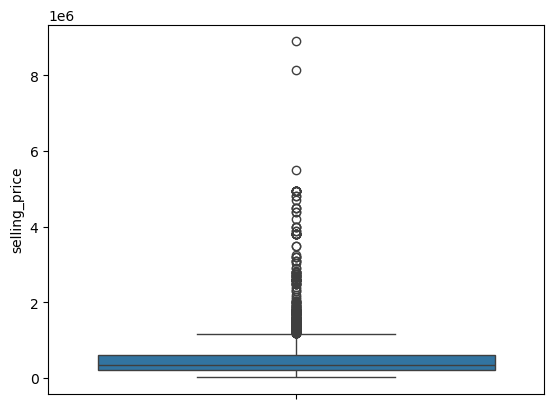

In [33]:
sns.boxplot(df['selling_price'])

In [34]:
# 1. Calculate Q1 (25th percentile) and Q3 (75th percentile) for selling_price
Q1 = df['selling_price'].quantile(0.25)
Q3 = df['selling_price'].quantile(0.75)
IQR = Q3 - Q1

# 2. Define lower and upper bounds
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# 3. Filter the dataframe to keep only values within the bounds
df_cleaned = df[(df['selling_price'] >= lower_bound) & (df['selling_price'] <= upper_bound)]

print(f"Original row count: {df.shape[0]}")
print(f"Cleaned row count: {df_cleaned.shape[0]}")

# 4. Preprocess the cleaned dataframe (errors='ignore' prevents the KeyError if 'name' was already dropped)
df_processed = df_cleaned.drop(columns=['name'], errors='ignore')
df_processed = pd.get_dummies(df_processed, drop_first=True)

# 5. Define features (X) and target (y)
X = df_processed.drop(columns=['selling_price'])
y = df_processed['selling_price']

# 6. Split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 7. Feature Scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 8. Train Model
model = LinearRegression()
model.fit(X_train_scaled, y_train)

# 9. Predict and Evaluate
y_pred = model.predict(X_test_scaled)
print(f"MAE: {mean_absolute_error(y_test, y_pred):.2f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test, y_pred)):.2f}")
print(f"R² Score: {r2_score(y_test, y_pred):.4f}")

Original row count: 4340
Cleaned row count: 4069
MAE: 121871.46
RMSE: 163776.99
R² Score: 0.5370


In [35]:
# मेट्रिक्स हिसाब गर्ने
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"MAE (Mean Absolute Error): {mae:.2f}")
print(f"RMSE (Root Mean Squared Error): {rmse:.2f}")
print(f"R² Score: {r2:.4f}")

MAE (Mean Absolute Error): 121871.46
RMSE (Root Mean Squared Error): 163776.99
R² Score: 0.5370


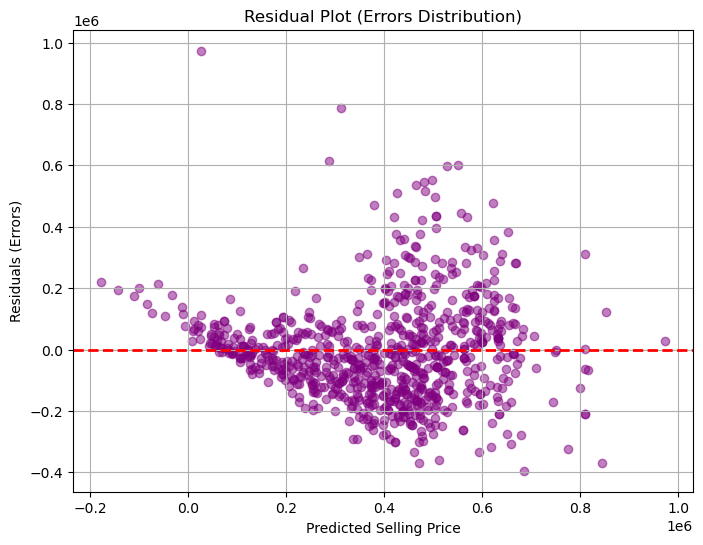

In [36]:
residuals = y_test - y_pred

plt.figure(figsize=(8, 6))
plt.scatter(y_pred, residuals, color='purple', alpha=0.5)
plt.axhline(y=0, color='red', linestyle='--', lw=2)
plt.xlabel('Predicted Selling Price')
plt.ylabel('Residuals (Errors)')
plt.title('Residual Plot (Errors Distribution)')
plt.grid(True)
plt.show()

In [37]:
'''
Regression Model Regurarization
-----------------------------------
1.Cross Validation
   -> If our dataset is small to medium sized.(0 to 40000)
   ->Make model learn multiple patterns of same data
2.Polynomial Regression
->If our data contains any non-linear features and has outliers.

3.Ridge Regression(L1)
-> Converts high weight data number to near zero .To reduce baisness and handle outliers

4.Lasso Regression
-> Removes high weightg data.

5.Elastic Not Regression
->Combination of ridge and lasso Regression.

6.Adjusting Cost Function / R2 Score 
->Formula
------
1-(1-r2)*(n-1))/(n - p -1)

r2 -> R2 score
n-> Sample (Test Data Samaple)
p -> Population(Train Data Population)
Formula 
-------------
1-((1-r2))*(n-1))/(n-p-1)

r2-> R2 Score 
n - Sample (Test Data Sample)
p->Population (Train Data Population)

'''

'\nRegression Model Regurarization\n-----------------------------------\n1.Cross Validation\n   -> If our dataset is small to medium sized.(0 to 40000)\n   ->Make model learn multiple patterns of same data\n2.Polynomial Regression\n->If our data contains any non-linear features and has outliers.\n\n3.Ridge Regression(L1)\n-> Converts high weight data number to near zero .To reduce baisness and handle outliers\n\n4.Lasso Regression\n-> Removes high weightg data.\n\n5.Elastic Not Regression\n->Combination of ridge and lasso Regression.\n\n6.Adjusting Cost Function / R2 Score \n->Formula\n------\n1-(1-r2)*(n-1))/(n - p -1)\n\nr2 -> R2 score\nn-> Sample (Test Data Samaple)\np -> Population(Train Data Population)\nFormula \n-------------\n1-((1-r2))*(n-1))/(n-p-1)\n\nr2-> R2 Score \nn - Sample (Test Data Sample)\np->Population (Train Data Population)\n\n'

In [38]:
print(df.columns)

Index(['year', 'selling_price', 'km_driven', 'fuel', 'seller_type',
       'transmission', 'owner'],
      dtype='object')


In [39]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# Scale 'km_driven' and 'year'
df[['km_driven', 'year']] = scaler.fit_transform(df[['km_driven', 'year']])

In [40]:
df['km_driven_scaled'] = (df['km_driven'] - df['km_driven'].mean()) / df['km_driven'].std()

In [41]:
X = df.drop(['selling_price', 'km_driven_scaled'], axis=1)
Y = df['selling_price']

print("X shape:", X.shape)
print("Y shape:", Y.shape)

X shape: (4340, 6)
Y shape: (4340,)


In [42]:
X = pd.get_dummies(
    X,
    columns=['fuel', 'seller_type', 'transmission', 'owner'],
    drop_first=True,
    dtype=int
)

In [43]:
print(X.head())
print(X.dtypes)
print(X.shape)

       year  km_driven  fuel_Diesel  fuel_Electric  fuel_LPG  fuel_Petrol  \
0 -1.445074   0.081139            0              0         0            1   
1 -1.445074  -0.347689            0              0         0            1   
2 -0.258795   0.724381            1              0         0            0   
3  0.927485  -0.433455            0              0         0            1   
4  0.215717   1.603479            1              0         0            0   

   seller_type_Individual  seller_type_Trustmark Dealer  transmission_Manual  \
0                       1                             0                    1   
1                       1                             0                    1   
2                       1                             0                    1   
3                       1                             0                    1   
4                       1                             0                    1   

   owner_Fourth & Above Owner  owner_Second Owner  owner

In [44]:
poly_features = Pipeline([
    ('scaler', StandardScaler()),
    ('poly', PolynomialFeatures(degree=2, include_bias=False)),
    ('linear', LinearRegression())
])

## Cross Validation

In [45]:
kfold = KFold(n_splits=5, shuffle=True, random_state=42)

cv_score = cross_val_score(
    poly_features,
    X,
    Y,
    cv=kfold,
    scoring='r2'
)

print(f'Cross Validation Scores: {cv_score}')
print(f'Average Cross Validation Score: {cv_score.mean()}')

Cross Validation Scores: [0.4669897  0.65781409 0.58003713 0.62311536 0.5765623 ]
Average Cross Validation Score: 0.5809037157816148


## Polynomial Regression

In [46]:
# Independent variables
X = df.drop(['selling_price', 'km_driven_scaled'], axis=1)

# Dependent variable
Y = df['selling_price']

# Convert categorical columns into numerical columns
X = pd.get_dummies(
    X,
    columns=['fuel', 'seller_type', 'transmission', 'owner'],
    drop_first=True,
    dtype=int
)

print("X shape:", X.shape)
print("Y shape:", Y.shape)

X shape: (4340, 13)
Y shape: (4340,)


In [47]:
from sklearn.model_selection import train_test_split

X_train, X_test, Y_train, Y_test = train_test_split(
    X,
    Y,
    test_size=0.2,
    random_state=42
)

print("X_train:", X_train.shape)
print("Y_train:", Y_train.shape)
print("X_test:", X_test.shape)
print("Y_test:", Y_test.shape)

X_train: (3472, 13)
Y_train: (3472,)
X_test: (868, 13)
Y_test: (868,)


In [48]:
from sklearn.linear_model import Ridge

ridge_model = Pipeline([
    ('scaler', StandardScaler()),
    ('ridge', Ridge(alpha=1.0))
])

ridge_model.fit(X_train, Y_train)

ridge_pred = ridge_model.predict(X_test)

ridge_r2 = r2_score(Y_test, ridge_pred)

print("Ridge Regression R2 Score:", ridge_r2)

Ridge Regression R2 Score: 0.40314770312915427


In [49]:
poly_features = Pipeline([
    ('scaler', StandardScaler()),

    # degree=2 -> To find non-linear patterns
    ('poly', PolynomialFeatures(degree=2, include_bias=False)),

    ('linear', LinearRegression())
])

# Train the model
poly_features.fit(X_train, Y_train)

# Make predictions
poly_pred = poly_features.predict(X_test)

# Calculate R2 score
poly_r2 = r2_score(Y_test, poly_pred)

# Calculate Adjusted R2
n_sample = X_test.shape[0]
p_date = X_test.shape[1]

adjust_poly_r2 = adjust_r2_score(poly_r2, n_sample, p_date)

print(f'Polynomial R2 Score: {poly_r2}')
print(f'Adjusted Polynomial R2 Score: {adjust_poly_r2}')

Polynomial R2 Score: 0.4669897025124774
Adjusted Polynomial R2 Score: 0.45887596262098107


# Polynomial Regression

In [50]:
poly_features = Pipeline([
('scaler', StandardScaler()),
    # degree=2-> To find non-linear patterns.
    ('poly',PolynomialFeatures(degree=2,include_bias=False)),
    ('linear',LinearRegression())

    
])

In [51]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. Split X and Y together using the exact same indices
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=42)

# 2. Scale X
scaler = StandardScaler()
X_train_scale = scaler.fit_transform(X_train)
X_test_scale = scaler.transform(X_test)

# 3. Now your pipeline will fit successfully
poly_features.fit(X_train_scale, Y_train)
poly_pred = poly_features.predict(X_test_scale)

## Ridge Regression

In [52]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import r2_score

ridge_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('ridge', Ridge(alpha=0.1))
])

# Train the model
ridge_pipeline.fit(X_train, Y_train)

# Make predictions
ridge_pred = ridge_pipeline.predict(X_test)

# Calculate R2 score
ridge_r2 = r2_score(Y_test, ridge_pred)

print(f'Ridge Regression R2 Score: {ridge_r2}')
print(f'Adjusted Lassso Regression R2 Score:{adjust_lasso_r2}')

Ridge Regression R2 Score: 0.40313209464946465


NameError: name 'adjust_lasso_r2' is not defined

# Lasso Regression

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Lasso
from sklearn.metrics import r2_score

# 1. Define Lasso Pipeline
lasso_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('lasso', Lasso(alpha=0.1))
])

# 2. Train and predict
lasso_pipeline.fit(X_train, Y_train)
lasso_pred = lasso_pipeline.predict(X_test)

# 3. Calculate scores
lasso_r2 = r2_score(Y_test, lasso_pred)
adjust_lasso_r2 = adjust_r2_score(lasso_r2, n_sample, p_data)

print(f'Lasso Regression R2 Score: {lasso_r2}')
print(f'Adjusted Lasso Regression R2 Score: {adjust_lasso_r2}')

## Elastic Net

In [ ]:
from sklearn.linear_model import ElasticNet
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score

elastic_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('elastic', ElasticNet(alpha=0.1, l1_ratio=0.5))
])

# Train the model
elastic_pipeline.fit(X_train, Y_train)

# Make predictions
elastic_pred = elastic_pipeline.predict(X_test)

# Calculate R2 score
elastic_r2 = r2_score(Y_test, elastic_pred)

print(f'Elastic Net Regression R2 Score: {elastic_r2}')

# Visaulization

In [ ]:
print("Y_test shape:", Y_test.shape)
print("Y_pred shape:", Y_pred.shape)
print("poly_pred shape:", poly_pred.shape)
print("ridge_pred shape:", ridge_pred.shape)
print("elastic_pred shape:", elastic_pred.shape)

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

linear_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('linear', LinearRegression())
])

# Train model
linear_pipeline.fit(X_train, Y_train)

# Predict values
Y_pred = linear_pipeline.predict(X_test)

print("Actual values:", len(Y_test))
print("Predicted values:", len(Y_pred))

In [ ]:
fig, axes= plt.subplots(3,2,figsize=(14,12))
plt.subplots_adjust(hspace=0.3)


ax1 = axes[0,0]
sns.regplot(x=Y_test,y=Y_pred, ax=ax1, color = 'blue',line_kws={'color':'red'})
ax1.set_title('House Price Prediction - Linear Regression')
ax1.set_xlabel('Actual House Price')
ax1.set_ylabel('Predicted House Price')
axes[0, 0].set_ylabel('Predicted Selling Price');

ax2 = axes[0,1]
sns.regplot(x=Y_test,y=poly_pred, ax=ax2, color = 'blue',line_kws={'color':'red'})
ax2.set_title('House Price Prediction - polynomial Regression')
ax2.set_xlabel('Actual House Price')
ax2.set_ylabel('Predicted House Price')
# axes[0, 0].set_ylabel('Predicted Selling Price');

ax3 = axes[1,0]
sns.regplot(x=Y_test,y=ridge_pred, ax=ax3, color = 'blue',line_kws={'color':'red'})
ax3.set_title('House Price Prediction - Ridge Regression')
ax3.set_xlabel('Actual House Price')
ax3.set_ylabel('Predicted House Price')
# axes[0, 0].set_ylabel('Predicted Selling Price');

ax4 = axes[1,1]
sns.regplot(x=Y_test,y=poly_pred, ax=ax4, color = 'blue',line_kws={'color':'red'})
ax4.set_title('House Price Prediction - Lasso Regression')
ax4.set_xlabel('Actual House Price')
ax4.set_ylabel('Predicted House Price')
# axes[0, 0].set_ylabel('Predicted Selling Price');

ax5 = axes[2,0]
sns.regplot(x=Y_test,y=poly_pred, ax=ax5, color = 'blue',line_kws={'color':'red'})
ax5.set_title('House Price Prediction - Elastic Net Regression')
ax5.set_xlabel('Actual House Price')
ax5.set_ylabel('Predicted House Price')
# axes[0, 0].set_ylabel('Predicted Selling Price');

plt.show()

In [53]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

In [55]:
dt_model = DecisionTreeRegressor(max_depth=5, random_state = 42)
dt_model.fit(X_train_scale,Y_train)
dt_pred = dt_model.predict(X_test_scale)

In [57]:
rf_model = RandomForestRegressor(max_depth =5,n_estimators=100,random_state=42)
rf_model.fit(X_train_scale,Y_train)
rf_pred = rf_model.predict(X_test_scale)


In [58]:
dt_r2 = r2_score(Y_test,dt_pred)
rf_r2 = r2_score(Y_test,rf_pred)

In [59]:
print(dt_r2)
print(rf_r2)

0.44612272813116083
0.4794901981198949
